# MLS Walk-Forward Research

This results notebook contains saved outputs from the reproducible experiment. Output tables and figures were generated from `artifacts/` by the research pipeline; run the code cells in a Jupyter environment to refresh them.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'artifacts').exists(): ROOT = ROOT.parent
ART = ROOT / 'artifacts'
metrics = pd.read_csv(ART / 'model_metrics.csv')
audit = json.loads((ART / 'data_audit.json').read_text(encoding='utf-8'))
predictions = pd.read_csv(ART / 'predictions.csv')
print(f"Regular-season matches: {audit['regular_season_rows']:,}; test seasons: {audit['evaluation']['test_seasons']}")
print(f"Verification: {audit['verification']['status']}")
display(metrics.sort_values('log_loss'))

Regular-season matches: 5,732; test seasons: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Verification: PASS


model,display_name,n_matches,accuracy,log_loss,brier,ranked_probability_score,top_label_ece_10,classwise_ece_10,bootstrap_delta_log_loss_vs_prior,bootstrap_delta_log_loss_ci95_low,bootstrap_delta_log_loss_ci95_high,home_goal_mae,away_goal_mae,home_goal_poisson_nll,away_goal_poisson_nll
league_prior,League prior,3641,0.4710,1.0609,0.6402,0.2252,0.0371,0.0247,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN
elo_raw,Elo (raw),3641,0.4518,1.0627,0.6410,0.2256,0.0210,0.0322,0.0018,-0.0070,0.0108,NaN,NaN,NaN,NaN
elo_temp,Elo (temperature scaled),3641,0.4518,1.0631,0.6413,0.2257,0.0268,0.0317,0.0021,-0.0066,0.0113,NaN,NaN,NaN,NaN
dixon_coles_temp,Dixon-Coles (temperature scaled),3641,0.4644,1.0638,0.6416,0.2259,0.0281,0.0265,0.0029,-0.0038,0.0094,1.0477,0.8884,1.6200,1.4557
logistic_temp,Team logistic (temperature scaled),3641,0.4633,1.0653,0.6425,0.2250,0.0173,0.0289,0.0044,-0.0023,0.0109,NaN,NaN,NaN,NaN
dixon_coles_raw,Dixon-Coles (raw),3641,0.4644,1.0687,0.6448,0.2274,0.0472,0.0382,0.0078,0.0007,0.0146,1.0477,0.8884,1.6200,1.4557
logistic_raw,Team logistic (raw),3641,0.4633,1.0763,0.6491,0.2279,0.0519,0.0457,0.0154,0.0075,0.0232,NaN,NaN,NaN,NaN


## Temporal and probability checks

The calibration cutoffs and game-ID partitions are measured on the saved run, not hand-entered.

In [ ]:
display(pd.DataFrame(audit['verification']['checks']))
assert audit['verification']['status'] == 'PASS'
assert audit['evaluation']['calibration_max_season_before_test_for_all']
assert audit['evaluation']['train_test_game_id_overlap_absent']

name,passed,max_abs_error,detail
annual expanding-window cutoff,True,NaN,NaN
train/test game-id separation,True,NaN,NaN
temperature fit uses prior seasons only,True,NaN,NaN
"all probabilities in [0,1]",True,NaN,NaN
probability vectors sum to one,True,2.220446e-16,NaN
post-match fields excluded from model inputs,True,NaN,Scores are used only as training labels / training outcomes; test scores are never passed to predictors.
hyperparameters pre-registered in code,True,NaN,No tuning on outer test seasons; constants are fixed in the package.


## Reproduce the full research run

Run this cell to refetch no data and rebuild the models, metrics, figures, PDFs, and marketing outputs from the local raw snapshot. It takes a few minutes.

In [ ]:
from sports_quant_lab.research import run_research
result = run_research(build_notebook=False)
metrics = result['metrics']
audit = result['audit']
display(metrics.sort_values('log_loss'))

model,display_name,n_matches,accuracy,log_loss,brier,ranked_probability_score,top_label_ece_10,classwise_ece_10,bootstrap_delta_log_loss_vs_prior,bootstrap_delta_log_loss_ci95_low,bootstrap_delta_log_loss_ci95_high,home_goal_mae,away_goal_mae,home_goal_poisson_nll,away_goal_poisson_nll
league_prior,League prior,3641,0.4710,1.0609,0.6402,0.2252,0.0371,0.0247,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN
elo_raw,Elo (raw),3641,0.4518,1.0627,0.6410,0.2256,0.0210,0.0322,0.0018,-0.0070,0.0108,NaN,NaN,NaN,NaN
elo_temp,Elo (temperature scaled),3641,0.4518,1.0631,0.6413,0.2257,0.0268,0.0317,0.0021,-0.0066,0.0113,NaN,NaN,NaN,NaN
dixon_coles_temp,Dixon-Coles (temperature scaled),3641,0.4644,1.0638,0.6416,0.2259,0.0281,0.0265,0.0029,-0.0038,0.0094,1.0477,0.8884,1.6200,1.4557
logistic_temp,Team logistic (temperature scaled),3641,0.4633,1.0653,0.6425,0.2250,0.0173,0.0289,0.0044,-0.0023,0.0109,NaN,NaN,NaN,NaN
dixon_coles_raw,Dixon-Coles (raw),3641,0.4644,1.0687,0.6448,0.2274,0.0472,0.0382,0.0078,0.0007,0.0146,1.0477,0.8884,1.6200,1.4557
logistic_raw,Team logistic (raw),3641,0.4633,1.0763,0.6491,0.2279,0.0519,0.0457,0.0154,0.0075,0.0232,NaN,NaN,NaN,NaN


Reproduction is a deterministic rerun from the included ASA raw snapshot.


## Aggregate result

The lowest aggregate held-out log loss in this run was **League prior: 1.0609** over 3,641 matches across 8 test seasons and 25,487 model-match predictions. The model comparison remains a historical sample result; paired uncertainty and per-season diagnostics should be read with it.

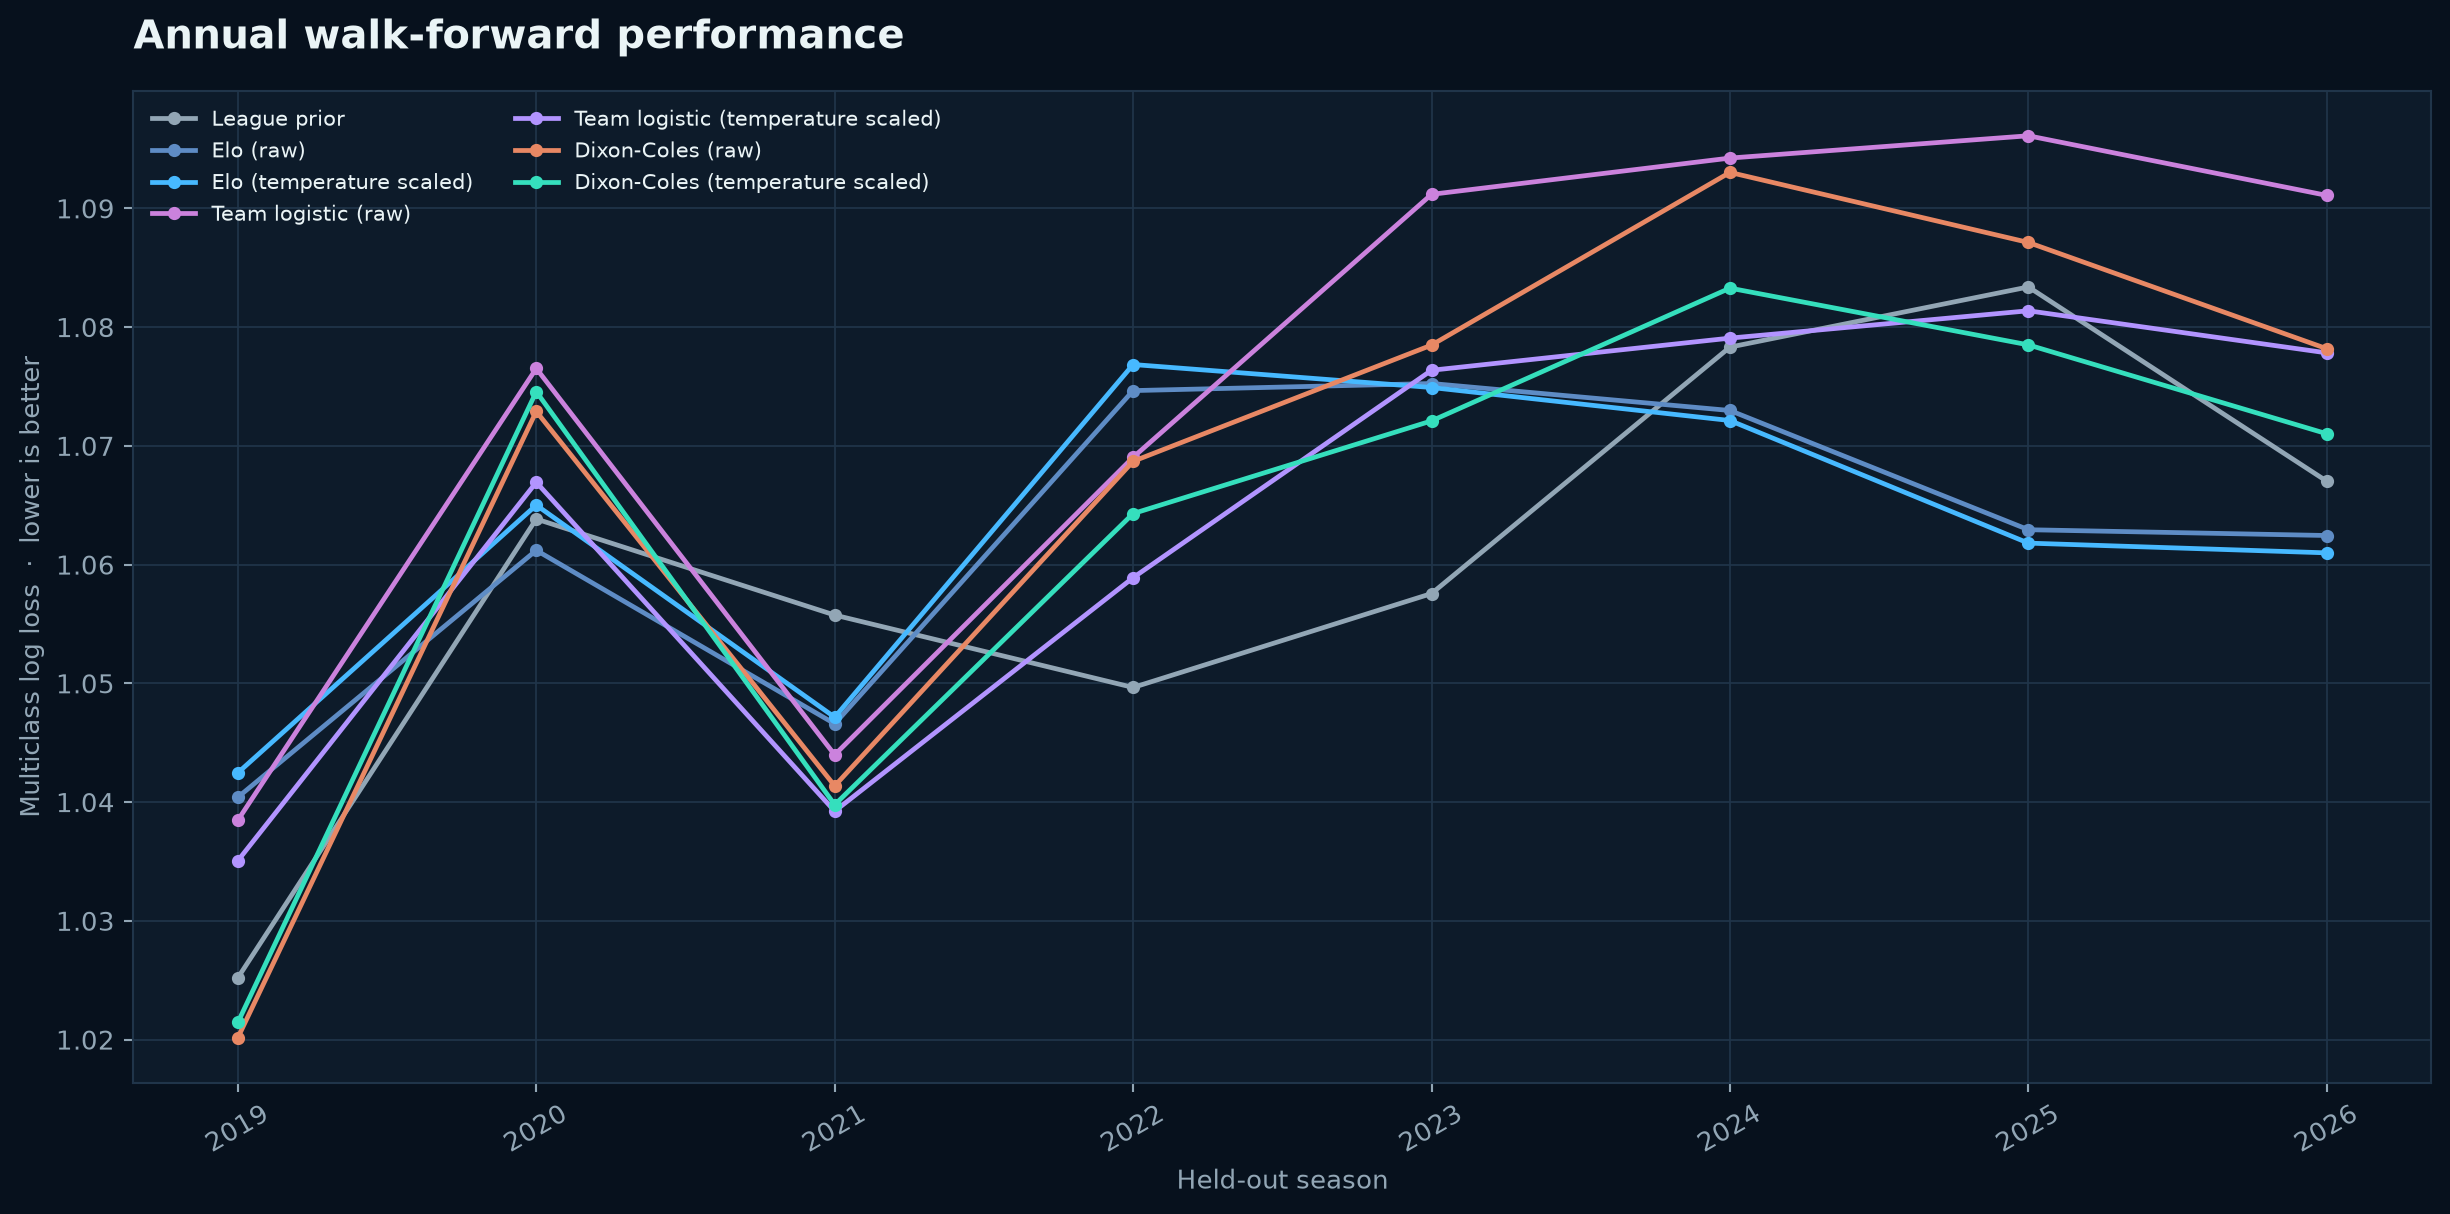

In [ ]:
import matplotlib.pyplot as plt
seasonal = pd.read_csv(ART / 'metrics_by_season.csv')
fig, ax = plt.subplots(figsize=(11, 5))
for name, rows in seasonal.groupby('display_name'):
    rows = rows.sort_values('season')
    ax.plot(rows.season, rows.log_loss, marker='o', label=name)
ax.set(title='Annual walk-forward log loss', xlabel='Held-out season', ylabel='Log loss (lower is better)')
ax.legend(ncol=2, fontsize=8, frameon=False)
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Calibration and scoreline diagnostics

The following saved figures are generated only from held-out predictions.

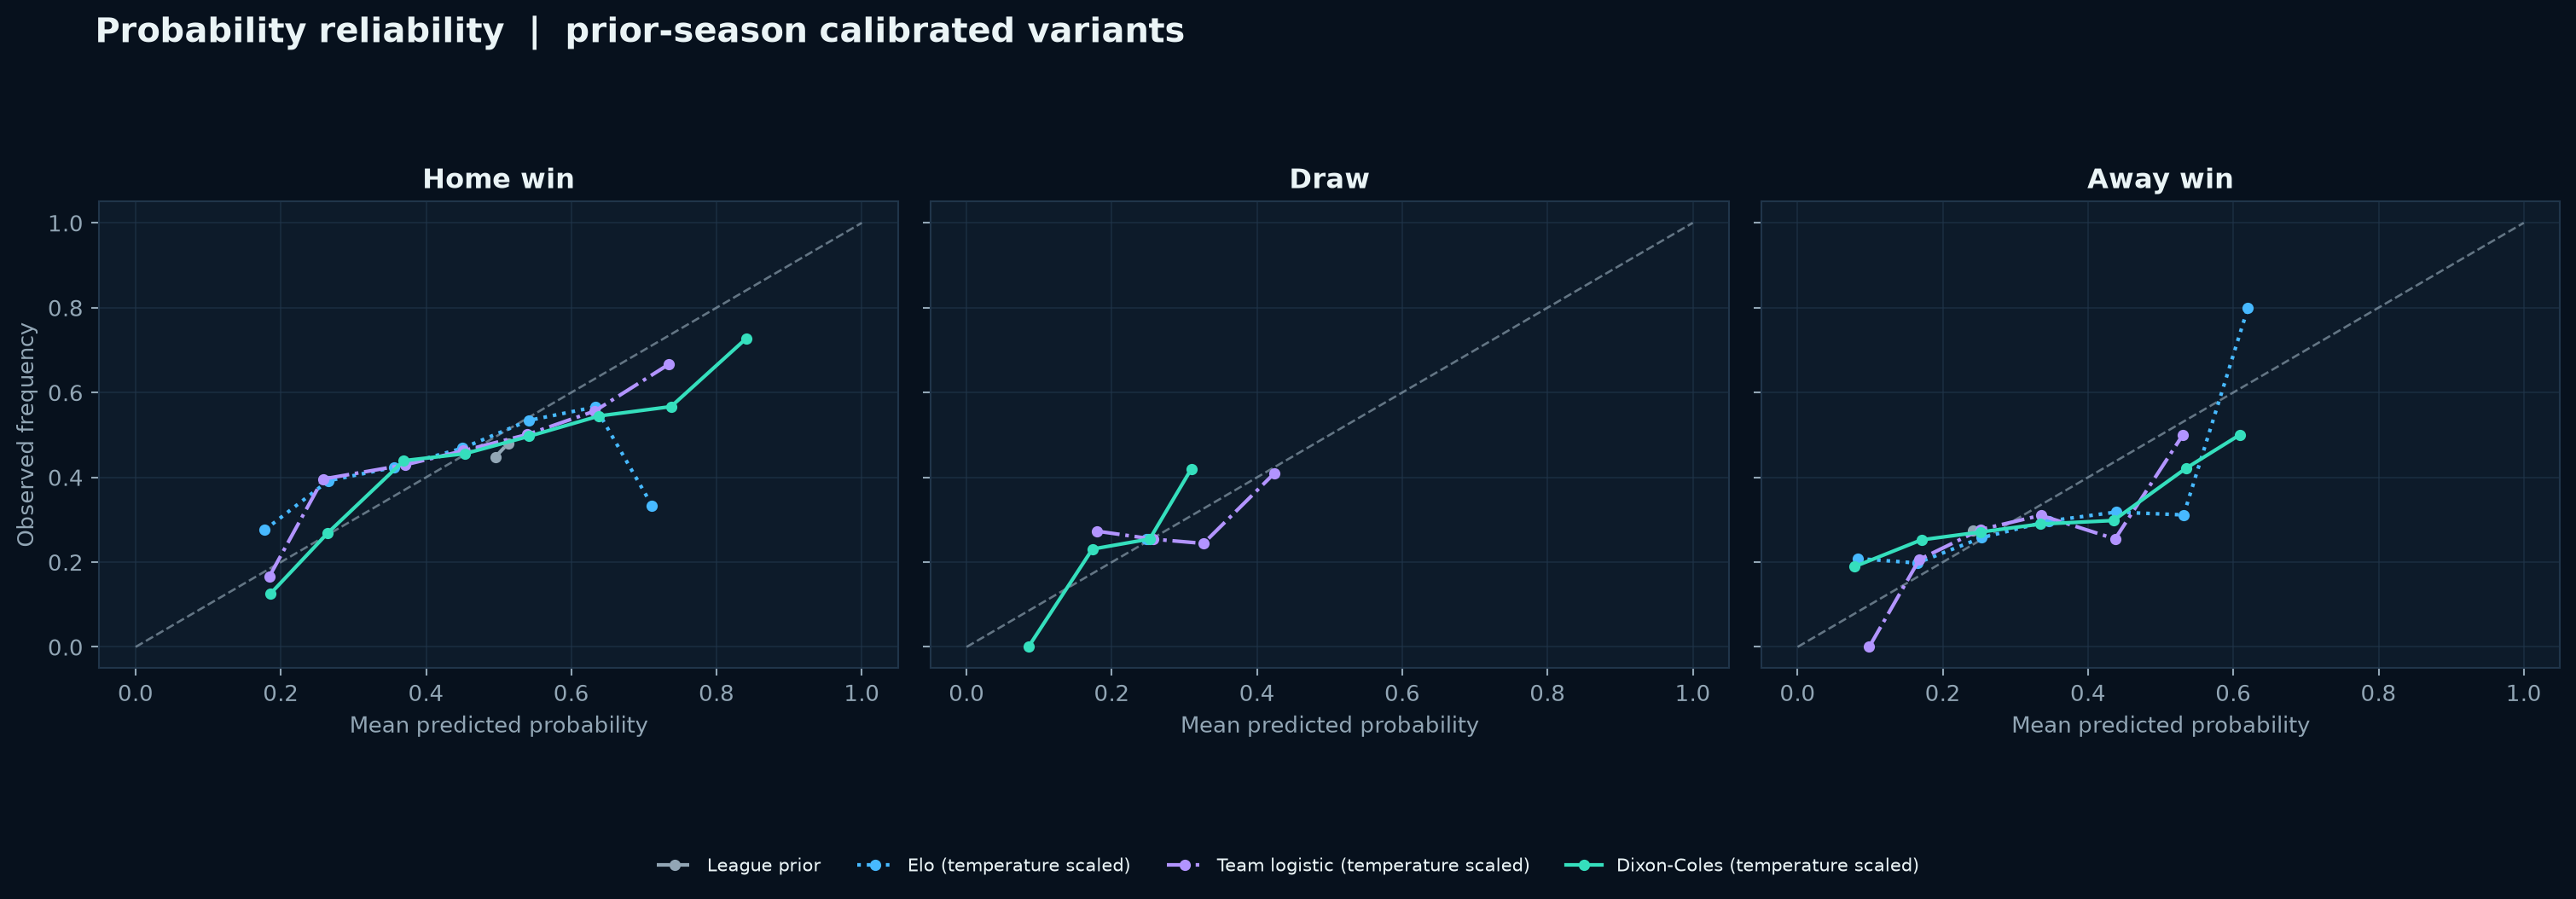

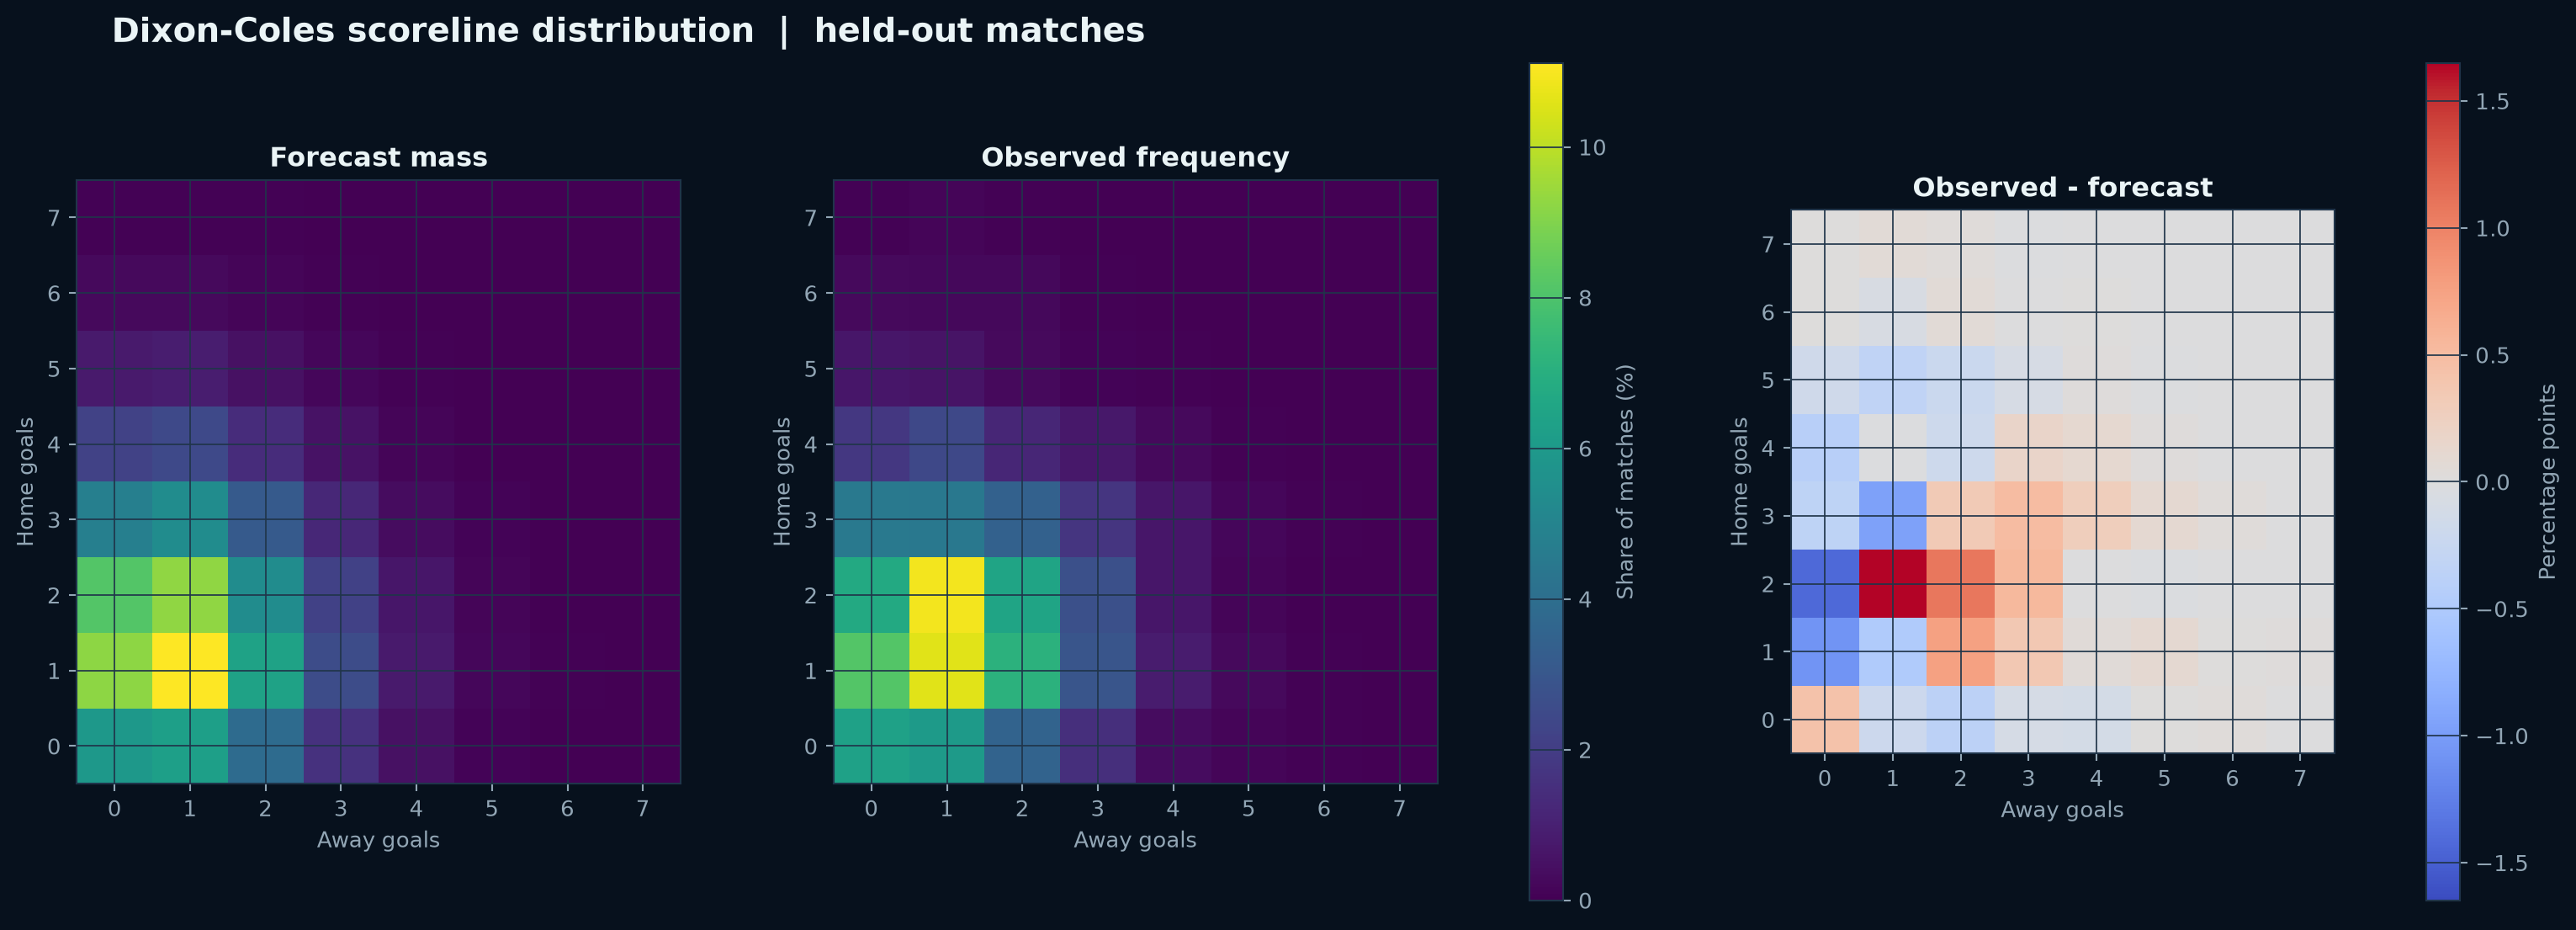

In [ ]:
display(Image(filename=str(ART / 'figures' / 'calibration_curve.png')))
display(Image(filename=str(ART / 'figures' / 'score_distribution.png')))

## Data limits

American Soccer Analysis provides current records and `last_updated_utc`, but no archived point-in-time versions. Season-level separation prevents direct future-result leakage; it cannot exclude every later revision to older records. No timestamped market prices are included, so the research makes no market-edge or betting-return claim.